In [1]:
!pip install -q lightgbm shap

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os, re, random, hashlib, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
pd.set_option("display.max_colwidth", 120)
print("Imports OK")

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os, re, random, hashlib, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
pd.set_option("display.max_colwidth", 120)
print("Imports OK")

LEET = str.maketrans({"0": "o", "1": "i", "3": "e", "4": "a", "5": "s", "7": "t", "@": "a", "$": "s"})

URL_RE   = re.compile(r"(https?://\S+|www\.\S+|\b[\w-]+\.(?:xyz|top|in|com|co|ly|link|site|online|club|info)\S*|\bbit\.ly/\S+|\bwa\.me/\S+)")
PHONE_RE = re.compile(r"(?<!\d)(?:\+?91[\s-]?)?[6-9][\dXx]{9}(?!\d)")
LONG_NUM = re.compile(r"\d{4,}")

def _deleet(m):
    t = m.group(0)
    if len(re.findall(r"[a-z]", t)) >= 3 and re.search(r"[0-9@$]", t):
        return t.translate(LEET)
    return t

def normalize(text):
    t = unicodedata.normalize("NFKC", str(text)).lower()
    t = URL_RE.sub(" urltoken ", t)
    t = PHONE_RE.sub(" phonetoken ", t)
    t = LONG_NUM.sub(" numtoken ", t)
    t = re.sub(r"[a-z0-9@$]+", _deleet, t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

tests = ["Ur a/c bl0cked, KYC upd@te now http://sbi-kyc.xyz",
         "Call 9876543210 to claim Rs 25,00,000",
         "Your OTP is 482913. Do not share."]
for s in tests:
    print(normalize(s))

Imports OK
ur a/c blocked, kyc update now urltoken
call phonetoken to claim rs 25,00,000
your otp is numtoken . do not share.


In [4]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
try:
    pub = pd.read_csv(URL, sep="\t", header=None, names=["label", "text"])
except Exception as e:
    print("URL failed:", e)
    from google.colab import files
    up = files.upload()
    pub = pd.read_csv(list(up.keys())[0], sep="\t", header=None, names=["label", "text"])

print(pub.shape)
print(pub["label"].value_counts())
print("Duplicates:", pub.duplicated().sum())

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64
Duplicates: 403


In [5]:
if os.path.exists("data/own_seed.csv"):
    own = pd.read_csv("data/own_seed.csv")
else:
    own = pd.DataFrame([
        ("spam", "Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi-kyc-update.xyz"),
        ("spam", "Ungal bank account block aagapogudhu. Udane KYC update pannunga: bit.ly/kyc-upd8"),
        ("ham",  "Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank"),
        ("ham",  "Machi, naalaiku evening 6 mani ku meet pannalam, ok va?"),
    ], columns=["label", "text"])
own.to_csv("data/own_seed.csv", index=False)
print("Real own messages:", len(own), "(target: 300+)")

Real own messages: 4 (target: 300+)


In [6]:
spam_T = [
 "Dear customer your {bank} a/c will be blocked today. Update KYC now {link}",
 "Ungal {bank} account block aagapogudhu. Udane KYC update pannunga: {link}",
 "Congrats! You won Rs {amt} in lottery. Call {ph} to claim your prize",
 "{wallet} KYC expired. Click {link} to avoid suspension",
 "Work from home job! Earn Rs {amt2} daily. WhatsApp {ph}",
 "Your courier is held due to incomplete address. Pay Rs {small} at {link}",
 "Instant loan Rs {amt} approved without documents. Install app {link}",
 "Electricity bill unpaid, power will be cut tonight 9.30pm. Call {ph} immediately",
 "Neenga {amt} rupees parisu jeithu irukeenga! Parisai pera inge click pannunga {link}",
 "Your SIM will be deactivated in 24 hrs. Complete verification {link}",
 "Income tax refund of Rs {amt} pending. Submit bank details {link}",
 "Dear {bank} user, PAN card update pending, a/c will be freezed. Login {link}",
]
ham_T = [
 "Your OTP for login is {otp}. Do not share it with anyone. - {bank} Bank",
 "Rs {amt2}.00 debited from A/c XX{acc} on {date}. UPI Ref {ref}. - {bank}",
 "Rs {amt2}.00 credited to A/c XX{acc} on {date}. - {bank}",
 "Machi, naalaiku evening {hr} mani ku meet pannalam, ok va?",
 "Your order has been shipped and will arrive by {day}. Track in the Amazon app.",
 "Amma ku medicine vaangitu vaa, pharmacy close aagum munnadi",
 "Your {telco} recharge of Rs {small2} is successful. Validity 28 days.",
 "Reminder: your appointment is on {day} at {hr}pm. Reply YES to confirm.",
 "{otp} is your OTP for UPI transaction of Rs {amt2}. Valid for 10 mins. Do not share. - {bank}",
 "Anna, meeting {day} shift aagirichu, {hr} mani ku varunga",
 "Your electricity bill of Rs {amt2} is paid successfully. Thank you. - TNEB",
 "Dear customer, your {bank} credit card statement for {date} is generated. Pay by due date in the app.",
]

def fill(t):
    d = dict(
        bank=random.choice(["SBI", "HDFC", "ICICI", "Axis", "Canara", "Indian Bank"]),
        wallet=random.choice(["Paytm", "PhonePe", "GPay"]),
        telco=random.choice(["Airtel", "Jio", "Vi", "BSNL"]),
        link=random.choice(["http://kyc-update.xyz", "bit.ly/a1b2c3", "http://bank-verify.top",
                            "https://secure-login.online/x9", "wa.me/919876500000"]),
        ph="9" + "".join(random.choices("0123456789", k=9)),
        amt=random.choice(["25,00,000", "10,00,000", "50000", "1,00,000"]),
        amt2=random.choice(["500", "1250", "3000", "5000", "799"]),
        small=random.choice(["10", "25", "49"]), small2=random.choice(["199", "239", "299", "719"]),
        otp="".join(random.choices("0123456789", k=6)), acc="".join(random.choices("0123456789", k=4)),
        ref="".join(random.choices("0123456789", k=9)),
        date=random.choice(["05-Oct", "12-Oct", "01-Nov", "17-Sep"]),
        day=random.choice(["Monday", "Tuesday", "Friday", "Saturday"]), hr=random.choice(["4", "5", "6", "7"]),
    )
    return t.format(**d)

syn = []
for label, templates in [(1, spam_T), (0, ham_T)]:
    for ti, t in enumerate(templates):
        for _ in range(25):
            syn.append((fill(t), label, f"syn_{label}_{ti}"))
syn = pd.DataFrame(syn, columns=["text", "label", "group"])
print(syn.shape, syn.label.value_counts().to_dict())
print(syn.sample(4, random_state=SEED)[["text", "label"]])

(600, 3) {1: 300, 0: 300}
                                                                                text  \
110                      Work from home job! Earn Rs 1250 daily. WhatsApp 9829694178   
419  Your order has been shipped and will arrive by Monday. Track in the Amazon app.   
565          Your electricity bill of Rs 799 is paid successfully. Thank you. - TNEB   
77                        Paytm KYC expired. Click bit.ly/a1b2c3 to avoid suspension   

     label  
110      1  
419      0  
565      0  
77       1  


In [7]:
a = pub.copy()
a["label"] = a["label"].map({"ham": 0, "spam": 1})
a["source"] = "uci"

b = own.copy()
b["label"] = b["label"].map({"ham": 0, "spam": 1})
b["source"] = "own_real"

c = syn[["text", "label"]].copy()
c["source"] = "synthetic"

full = pd.concat([a, b, c], ignore_index=True)
full["norm"] = full["text"].map(normalize)

# group: duplicates / near-duplicates same group, synthetic = template group
grp = full["norm"].map(lambda s: hashlib.md5(s.encode()).hexdigest()[:10])
syn_groups = pd.Series(list(syn["group"]), index=full.index[full["source"] == "synthetic"])
full["group"] = grp
full.loc[syn_groups.index, "group"] = syn_groups

before = len(full)
full = full.drop_duplicates(subset="norm").reset_index(drop=True)
print("Dedupe:", before, "->", len(full))
print(full.groupby(["source", "label"]).size())

Dedupe: 6176 -> 5309
source     label
own_real   0           2
           1           2
synthetic  0         121
           1          42
uci        0        4515
           1         627
dtype: int64


In [8]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [idx for _, idx in sgkf.split(full, full["label"], full["group"])]

test_idx, val_idx = folds[0], folds[1]
train_idx = np.concatenate(folds[2:])

train = full.loc[train_idx].reset_index(drop=True)
val   = full.loc[val_idx].reset_index(drop=True)
test  = full.loc[test_idx].reset_index(drop=True)

for n, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s} rows={len(d):5d} scam_rate={d.label.mean():.3f}  real_own={int((d.source=='own_real').sum())}")

# leakage check
assert not (set(train.group) & set(test.group)), "group leak!"
assert not (set(train.norm) & set(test.norm)), "text leak!"
print("No leakage OK")

train.to_csv("data/train.csv", index=False)
val.to_csv("data/val.csv", index=False)
test.to_csv("data/test.csv", index=False)

train rows= 3797 scam_rate=0.119  real_own=3
val   rows=  767 scam_rate=0.138  real_own=0
test  rows=  745 scam_rate=0.152  real_own=1
No leakage OK


In [9]:
from sklearn.preprocessing import StandardScaler

SHORTENERS = ["bit.ly", "tinyurl", "t.co", "goo.gl", "wa.me", "cutt.ly", "rb.gy"]
SUS_TLD = [".xyz", ".top", ".online", ".club", ".site", ".link", ".info"]
URGENT = ["urgent", "immediately", "today", "expire", "block", "suspend", "freez", "deactivat",
          "within 24", "last chance", "udane", "verify", "kyc", "aadhaar", "pan card", "claim",
          "prize", "won", "lottery", "winner", "congrat", "refund", "loan", "earn", "click",
          "pending", "penalty", "legal", "parisu", "install"]
RS_RE = re.compile(r"(?:rs\.?|inr|₹)\s*[\d,]+")

def hand_features(raw):
    t = str(raw)
    low = t.lower()
    n = max(len(t), 1)
    words = low.split()
    urls = URL_RE.findall(low)
    return {
        "len": len(t),
        "n_words": len(words),
        "digit_ratio": sum(c.isdigit() for c in t) / n,
        "upper_ratio": sum(c.isupper() for c in t) / n,
        "punct_ratio": sum((not c.isalnum()) and (not c.isspace()) for c in t) / n,
        "n_excl": t.count("!"),
        "n_urls": len(urls),
        "has_shortener": int(any(s in low for s in SHORTENERS)),
        "has_sus_tld": int(any(s in low for s in SUS_TLD)),
        "n_phones": len(PHONE_RE.findall(t)),
        "n_rs": len(RS_RE.findall(low)),
        "urgent_hits": sum(k in low for k in URGENT),
        "tamil_ratio": sum("\u0b80" <= c <= "\u0bff" for c in t) / n,
        "has_otp": int("otp" in low),
        "has_do_not_share": int("do not share" in low or "don't share" in low),
        "has_txn_words": int(any(k in low for k in ["debited", "credited", "upi ref", "a/c xx"])),
        "leet_hits": len(re.findall(r"[a-z]+[0@$][a-z]+", low)),
    }

def build_hand(d):
    return pd.DataFrame([hand_features(x) for x in d["text"]])

H_train, H_val, H_test = build_hand(train), build_hand(val), build_hand(test)
print(H_train.shape)
display(H_train.groupby(train["label"].values).mean().T.round(3))

(3797, 17)


,0,1
len,71.390,134.827
n_words,14.298,22.923
digit_ratio,0.006,0.109
upper_ratio,0.056,0.108
punct_ratio,0.060,0.047
n_excl,0.170,0.704
n_urls,0.004,0.265
has_shortener,0.000,0.024
has_sus_tld,0.000,0.046
n_phones,0.000,0.022


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                           sublinear_tf=True, max_features=150000)
word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                           sublinear_tf=True, max_features=50000,
                           token_pattern=r"[^\s.,!?;:()\"']+")
scaler = StandardScaler()

# FIT ON TRAIN ONLY
C_train = char_vec.fit_transform(train["norm"])
W_train = word_vec.fit_transform(train["norm"])
S_train = scaler.fit_transform(H_train)

def make_X(d, H):
    return hstack([char_vec.transform(d["norm"]),
                   word_vec.transform(d["norm"]),
                   csr_matrix(scaler.transform(H))]).tocsr()

X_train = hstack([C_train, W_train, csr_matrix(S_train)]).tocsr()
X_val   = make_X(val, H_val)
X_test  = make_X(test, H_test)

y_train, y_val, y_test = train["label"].values, val["label"].values, test["label"].values

print("char vocab:", len(char_vec.vocabulary_), "| word vocab:", len(word_vec.vocabulary_))
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("Same columns:", X_train.shape[1] == X_val.shape[1] == X_test.shape[1])

char vocab: 28663 | word vocab: 9745
X_train: (3797, 38425) | X_val: (767, 38425) | X_test: (745, 38425)
Same columns: True


In [11]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, matthews_corrcoef

def recall_at_fpr(y, p, target_fpr=0.01):
    fpr, tpr, thr = roc_curve(y, p)
    ok = np.where(fpr <= target_fpr)[0]
    i = ok[-1]
    return tpr[i], thr[i], fpr[i]

def report(y, p, name=""):
    rec, thr, f = recall_at_fpr(y, p, 0.01)
    pred = (p >= thr).astype(int)
    return {"model": name,
            "roc_auc": roc_auc_score(y, p),
            "pr_auc": average_precision_score(y, p),
            "recall@1%FPR": rec,
            "mcc@thr": matthews_corrcoef(y, pred)}

print("helpers ready")

helpers ready


In [12]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=10, max_iter=3000, class_weight="balanced", random_state=SEED)
lr.fit(X_train, y_train)
p_val = lr.predict_proba(X_val)[:, 1]

print(pd.DataFrame([report(y_val, p_val, "LogReg")]).round(4).to_string(index=False))

# source-wise breakdown (real vs uci vs synthetic)
for s in val["source"].unique():
    m = (val["source"] == s).values
    if m.sum() > 20 and len(np.unique(y_val[m])) == 2:
        print(f"{s:10s} n={m.sum():4d}  ROC-AUC={roc_auc_score(y_val[m], p_val[m]):.4f}")
    else:
        print(f"{s:10s} n={m.sum():4d}  (chinna / single-class, skip)")

 model  roc_auc  pr_auc  recall@1%FPR  mcc@thr
LogReg   0.9881   0.933        0.9245   0.9335
uci        n= 731  ROC-AUC=0.9897
synthetic  n=  36  ROC-AUC=1.0000


In [13]:
from sklearn.svm import LinearSVC
from sklearn.linear_model import SGDClassifier
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from lightgbm import LGBMClassifier

n_text = C_train.shape[1] + W_train.shape[1]   # char + word columns, handcrafted ku munnadi

class NBSVM(BaseEstimator, ClassifierMixin):
    """Naive-Bayes log-count-ratio scaled features + Logistic Regression"""
    def __init__(self, n_text=0, C=4.0, alpha=1.0):
        self.n_text = n_text
        self.C = C
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        Xt = X[:, :self.n_text]
        p = np.asarray(Xt[y == 1].sum(axis=0)).ravel() + self.alpha
        q = np.asarray(Xt[y == 0].sum(axis=0)).ravel() + self.alpha
        self.r_ = np.log((p / p.sum()) / (q / q.sum()))
        self.lr_ = LogisticRegression(C=self.C, max_iter=3000,
                                      class_weight="balanced", random_state=SEED)
        self.lr_.fit(Xt.multiply(self.r_).tocsr(), y)
        self.classes_ = self.lr_.classes_
        return self

    def decision_function(self, X):
        return self.lr_.decision_function(X[:, :self.n_text].multiply(self.r_).tocsr())

models = {
    "LogReg":   LogisticRegression(C=10, max_iter=3000, class_weight="balanced", random_state=SEED),
    "LinearSVC": LinearSVC(C=0.5, class_weight="balanced", random_state=SEED),
    "NB-SVM":   NBSVM(n_text=n_text, C=4.0),
    "SGD":      SGDClassifier(loss="modified_huber", alpha=1e-5, class_weight="balanced",
                              random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                               colsample_bytree=0.3, subsample=0.8, subsample_freq=1,
                               min_child_samples=5, n_jobs=-1, random_state=SEED, verbose=-1),
}

def get_score(m, X):
    if hasattr(m, "predict_proba"):
        return m.predict_proba(X)[:, 1]
    return m.decision_function(X)

print("Models:", list(models.keys()), "| n_text =", n_text)

Models: ['LogReg', 'LinearSVC', 'NB-SVM', 'SGD', 'LightGBM'] | n_text = 38408


In [14]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(cv.split(X_train, y_train, train["group"]))

cv_rows = []
for name, m in models.items():
    fold_res = []
    for tr, te in splits:
        mm = clone(m).fit(X_train[tr], y_train[tr])
        s = get_score(mm, X_train[te])
        fold_res.append(report(y_train[te], s, name))
    d = pd.DataFrame(fold_res)
    cv_rows.append({
        "model": name,
        "cv_roc_auc": d["roc_auc"].mean(),
        "cv_pr_auc": d["pr_auc"].mean(),
        "cv_rec@1%FPR": d["recall@1%FPR"].mean(),
        "rec_std": d["recall@1%FPR"].std(),
        "cv_mcc": d["mcc@thr"].mean(),
    })
    print(f"{name:10s} done")

cv_table = pd.DataFrame(cv_rows).sort_values("cv_pr_auc", ascending=False).round(4)
display(cv_table)

LogReg     done
LinearSVC  done
NB-SVM     done
SGD        done
LightGBM   done


,model,cv_roc_auc,cv_pr_auc,cv_rec@1%FPR,rec_std,cv_mcc
4,LightGBM,0.9929,0.9720,0.9142,0.0454,0.9268
0,LogReg,0.9892,0.9523,0.8548,0.1580,0.8809
2,NB-SVM,0.9873,0.9408,0.8016,0.2285,0.8476
1,LinearSVC,0.9883,0.9163,0.7711,0.3683,0.8137
3,SGD,0.9472,0.7758,0.1743,0.3897,0.1812


In [15]:
val_rows, fitted, val_scores = [], {}, {}
for name, m in models.items():
    mm = clone(m).fit(X_train, y_train)
    fitted[name] = mm
    val_scores[name] = get_score(mm, X_val)
    val_rows.append(report(y_val, val_scores[name], name))

display(pd.DataFrame(val_rows).sort_values("pr_auc", ascending=False).round(4))

print("\nSource-wise ROC-AUC (val):")
src_rows = []
for name, s in val_scores.items():
    row = {"model": name}
    for src in val["source"].unique():
        mask = (val["source"] == src).values
        if mask.sum() > 20 and len(np.unique(y_val[mask])) == 2:
            row[src] = roc_auc_score(y_val[mask], s[mask])
    src_rows.append(row)
display(pd.DataFrame(src_rows).round(4))

,model,roc_auc,pr_auc,recall@1%FPR,mcc@thr
4,LightGBM,0.9892,0.9734,0.9340,0.9392
2,NB-SVM,0.9857,0.9708,0.9151,0.9388
1,LinearSVC,0.9892,0.9393,0.9528,0.9506
0,LogReg,0.9881,0.9330,0.9245,0.9335
3,SGD,0.9681,0.8658,0.0000,0.0000



Source-wise ROC-AUC (val):


,model,uci,synthetic
0,LogReg,0.9897,1.0
1,LinearSVC,0.9900,1.0
2,NB-SVM,0.9873,1.0
3,SGD,0.9667,1.0
4,LightGBM,0.9913,1.0


In [16]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.9 MB/s eta 0:00:00


In [17]:
import optuna
from sklearn.metrics import average_precision_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

def raw_score(m, X):
    if hasattr(m, "decision_function"):
        return m.decision_function(X)
    p = np.clip(m.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

CW = {"none": None, "balanced": "balanced"}

def b_lr(t):
    cw = t.suggest_categorical("cw", ["none", "balanced"])
    C = t.suggest_float("C", 0.1, 100, log=True)
    return LogisticRegression(C=C, max_iter=3000, class_weight=CW[cw], random_state=SEED)

def b_svc(t):
    cw = t.suggest_categorical("cw", ["none", "balanced"])
    C = t.suggest_float("C", 0.01, 10, log=True)
    return LinearSVC(C=C, class_weight=CW[cw], random_state=SEED)

def b_nbsvm(t):
    C = t.suggest_float("C", 0.5, 50, log=True)
    a = t.suggest_float("alpha", 0.1, 2.0, log=True)
    return NBSVM(n_text=n_text, C=C, alpha=a)

def b_sgd(t):
    loss = t.suggest_categorical("loss", ["modified_huber", "hinge", "log_loss"])
    alpha = t.suggest_float("alpha", 1e-6, 1e-3, log=True)
    cw = t.suggest_categorical("cw", ["none", "balanced"])
    return SGDClassifier(loss=loss, alpha=alpha, class_weight=CW[cw], max_iter=2000, random_state=SEED)

def b_lgbm(t):
    return LGBMClassifier(
        n_estimators=t.suggest_int("n_estimators", 150, 400),
        learning_rate=t.suggest_float("lr", 0.02, 0.15, log=True),
        num_leaves=t.suggest_int("num_leaves", 7, 31),
        colsample_bytree=t.suggest_float("colsample", 0.1, 0.5),
        min_child_samples=t.suggest_int("min_child", 3, 20),
        reg_lambda=t.suggest_float("reg_lambda", 0.0, 5.0),
        subsample=0.8, subsample_freq=1,
        n_jobs=-1, random_state=SEED, verbose=-1)

builders = {"LogReg": b_lr, "LinearSVC": b_svc, "NB-SVM": b_nbsvm, "SGD": b_sgd, "LightGBM": b_lgbm}
budget_sec = {"LogReg": 120, "LinearSVC": 120, "NB-SVM": 120, "SGD": 120, "LightGBM": 300}
print("Spaces ready:", list(builders))

Spaces ready: ['LogReg', 'LinearSVC', 'NB-SVM', 'SGD', 'LightGBM']


In [18]:
def cv_pr(est):
    sc = []
    for tr, te in splits:
        mm = clone(est).fit(X_train[tr], y_train[tr])
        sc.append(average_precision_score(y_train[te], raw_score(mm, X_train[te])))
    return float(np.mean(sc))

studies = {}
for name, bld in builders.items():
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(lambda t: cv_pr(bld(t)), n_trials=40, timeout=budget_sec[name])
    studies[name] = st
    print(f"{name:10s} trials={len(st.trials):3d}  best CV PR-AUC={st.best_value:.4f}  {st.best_params}")

LogReg     trials= 11  best CV PR-AUC=0.9520  {'cw': 'balanced', 'C': 15.702970884055382}
LinearSVC  trials= 40  best CV PR-AUC=0.9278  {'cw': 'balanced', 'C': 0.04944399983990361}
NB-SVM     trials= 40  best CV PR-AUC=0.9640  {'C': 47.50730030171743, 'alpha': 0.10564770873171728}
SGD        trials= 40  best CV PR-AUC=0.9561  {'loss': 'modified_huber', 'alpha': 0.0003420003729910134, 'cw': 'none'}
LightGBM   trials=  7  best CV PR-AUC=0.9690  {'n_estimators': 244, 'lr': 0.1358198535217987, 'num_leaves': 25, 'colsample': 0.3394633936788146, 'min_child': 5, 'reg_lambda': 0.7799726016810132}


In [19]:
tuned = {n: builders[n](optuna.trial.FixedTrial(studies[n].best_params)) for n in builders}

fitted, val_s = {}, {}
for n, m in tuned.items():
    fitted[n] = clone(m).fit(X_train, y_train)
    val_s[n] = raw_score(fitted[n], X_val)

display(pd.DataFrame([report(y_val, val_s[n], n) for n in tuned])
        .sort_values("pr_auc", ascending=False).round(4))

,model,roc_auc,pr_auc,recall@1%FPR,mcc@thr
2,NB-SVM,0.9907,0.9810,0.9717,0.9619
4,LightGBM,0.9891,0.9717,0.9151,0.9332
0,LogReg,0.9880,0.9345,0.9340,0.9339
1,LinearSVC,0.9840,0.9237,0.8868,0.9105
3,SGD,0.9826,0.9110,0.8962,0.9054


In [20]:
names = list(tuned.keys())
Z_train = np.zeros((len(y_train), len(names)))

for j, n in enumerate(names):
    for tr, te in splits:
        mm = clone(tuned[n]).fit(X_train[tr], y_train[tr])
        Z_train[te, j] = raw_score(mm, X_train[te])
    print(n, "OOF done")

Z_val  = np.column_stack([raw_score(fitted[n], X_val)  for n in names])
Z_test = np.column_stack([raw_score(fitted[n], X_test) for n in names])

print("Z shapes:", Z_train.shape, Z_val.shape, Z_test.shape)
print("OOF corr:")
display(pd.DataFrame(Z_train, columns=names).corr().round(3))

LogReg OOF done
LinearSVC OOF done
NB-SVM OOF done
SGD OOF done
LightGBM OOF done
Z shapes: (3797, 5) (767, 5) (745, 5)
OOF corr:


,LogReg,LinearSVC,NB-SVM,SGD,LightGBM
LogReg,1.000,0.954,0.852,0.731,0.864
LinearSVC,0.954,1.000,0.888,0.566,0.924
NB-SVM,0.852,0.888,1.000,0.426,0.901
SGD,0.731,0.566,0.426,1.000,0.433
LightGBM,0.864,0.924,0.901,0.433,1.000


In [22]:
from sklearn.pipeline import make_pipeline

meta = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
meta.fit(Z_train, y_train)
stack_val = meta.decision_function(Z_val)

mu, sd = Z_train.mean(0), Z_train.std(0) + 1e-9
avg_val = ((Z_val - mu) / sd).mean(1)

coefs = meta[-1].coef_.ravel()
print("Meta weights:", dict(zip(names, coefs.round(3))))

rows = [report(y_val, val_s[n], n) for n in names]
rows += [report(y_val, avg_val, "Average(z)"), report(y_val, stack_val, "STACK")]
display(pd.DataFrame(rows).sort_values("pr_auc", ascending=False).round(4))

Meta weights: {'LogReg': np.float64(0.615), 'LinearSVC': np.float64(-2.271), 'NB-SVM': np.float64(2.014), 'SGD': np.float64(3.064), 'LightGBM': np.float64(2.351)}


,model,roc_auc,pr_auc,recall@1%FPR,mcc@thr
2,NB-SVM,0.9907,0.9810,0.9717,0.9619
6,STACK,0.9934,0.9810,0.9434,0.9503
4,LightGBM,0.9891,0.9717,0.9151,0.9332
5,Average(z),0.9903,0.9385,0.9434,0.9503
0,LogReg,0.9880,0.9345,0.9340,0.9339
1,LinearSVC,0.9840,0.9237,0.8868,0.9105
3,SGD,0.9826,0.9110,0.8962,0.9054


,method,brier,logloss,n_unique_scores
0,raw meta,0.0114,0.0478,767
1,Platt,0.0104,0.0478,767
2,Isotonic,0.0168,0.0640,19


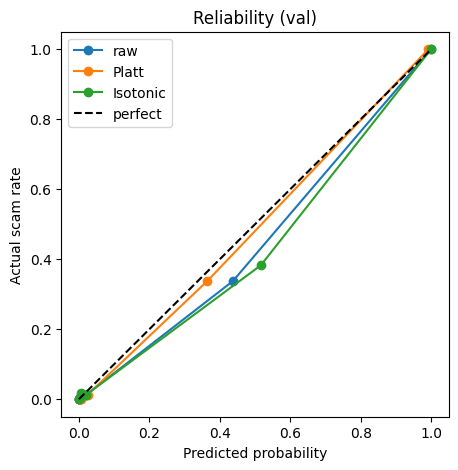

In [23]:
from sklearn.model_selection import cross_val_predict
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

meta_oof = cross_val_predict(meta, Z_train, y_train, cv=splits, method="decision_function")

platt = LogisticRegression(C=1e6, max_iter=1000).fit(meta_oof.reshape(-1, 1), y_train)
iso = IsotonicRegression(out_of_bounds="clip").fit(meta_oof, y_train)

p_raw   = 1 / (1 + np.exp(-stack_val))
p_platt = platt.predict_proba(stack_val.reshape(-1, 1))[:, 1]
p_iso   = np.clip(iso.predict(stack_val), 1e-4, 1 - 1e-4)

cal = pd.DataFrame({
    "method": ["raw meta", "Platt", "Isotonic"],
    "brier": [brier_score_loss(y_val, p) for p in (p_raw, p_platt, p_iso)],
    "logloss": [log_loss(y_val, p) for p in (p_raw, p_platt, p_iso)],
    "n_unique_scores": [len(np.unique(p)) for p in (p_raw, p_platt, p_iso)],
}).round(4)
display(cal)

plt.figure(figsize=(5, 5))
for p, lab in [(p_raw, "raw"), (p_platt, "Platt"), (p_iso, "Isotonic")]:
    fp, mp = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    plt.plot(mp, fp, marker="o", label=lab)
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("Predicted probability"); plt.ylabel("Actual scam rate")
plt.legend(); plt.title("Reliability (val)"); plt.show()

In [24]:
calibrated_val = p_platt

print("Overall (val):")
display(pd.DataFrame([report(y_val, calibrated_val, "STACK+Platt")]).round(4))

print("\nSource-wise ROC-AUC (val):")
rows = []
score_sets = {n: val_s[n] for n in names}
score_sets["STACK+Platt"] = calibrated_val
for n, s in score_sets.items():
    row = {"model": n}
    for src in val["source"].unique():
        m = (val["source"] == src).values
        if m.sum() > 20 and len(np.unique(y_val[m])) == 2:
            row[src] = roc_auc_score(y_val[m], s[m])
    rows.append(row)
display(pd.DataFrame(rows).round(4))

Overall (val):


,model,roc_auc,pr_auc,recall@1%FPR,mcc@thr
0,STACK+Platt,0.9934,0.981,0.9434,0.9503



Source-wise ROC-AUC (val):


,model,uci,synthetic
0,LogReg,0.9894,1.0
1,LinearSVC,0.9862,1.0
2,NB-SVM,0.9913,1.0
3,SGD,0.9844,1.0
4,LightGBM,0.9911,1.0
5,STACK+Platt,0.9949,1.0


In [25]:
p_oof = platt.predict_proba(meta_oof.reshape(-1, 1))[:, 1]

def thr_for_fpr(y, p, target=0.01):
    neg = np.sort(p[y == 0])
    k = int(np.ceil((1 - target) * len(neg))) - 1
    return neg[k]                      # predict scam if p > thr

def eval_at(y, p, thr):
    pred = p > thr
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return {"recall": tp / max(tp + fn, 1), "FPR": fp / max(fp + tn, 1),
            "precision": tp / max(tp + fp, 1), "TP": tp, "FP": fp, "FN": fn, "TN": tn}

rows = []
for tgt in [0.005, 0.01, 0.02, 0.05]:
    thr = thr_for_fpr(y_train, p_oof, tgt)
    r = eval_at(y_val, p_platt, thr)
    rows.append({"target_FPR": tgt, "thr": round(thr, 4), **{k: round(v, 4) if isinstance(v, float) else v for k, v in r.items()}})
display(pd.DataFrame(rows))

THR = thr_for_fpr(y_train, p_oof, 0.01)
print("\nFINAL THRESHOLD (1% FPR, from OOF):", round(THR, 5))
print("Legit msgs in OOF:", int((y_train == 0).sum()), "| legit in val:", int((y_val == 0).sum()))

,target_FPR,thr,recall,FPR,precision,TP,FP,FN,TN
0,0.005,0.8851,0.8585,0.0000,1.0000,91,0,15,661
1,0.010,0.2260,0.9623,0.0121,0.9273,102,8,4,653
2,0.020,0.0823,0.9623,0.0590,0.7234,102,39,4,622
3,0.050,0.0347,0.9811,0.0938,0.6265,104,62,2,599



FINAL THRESHOLD (1% FPR, from OOF): 0.22605
Legit msgs in OOF: 3345 | legit in val: 661


In [26]:
def predict_texts(texts):
    d = pd.DataFrame({"text": [str(t) for t in texts]})
    d["norm"] = d["text"].map(normalize)
    H = build_hand(d)
    X = make_X(d, H)
    Z = np.column_stack([raw_score(fitted[n], X) for n in names])
    s = meta.decision_function(Z)
    return platt.predict_proba(s.reshape(-1, 1))[:, 1]

# consistency check: same as Step 5 val scores
chk = predict_texts(val["text"])
print("Matches Step 5:", np.allclose(chk, p_platt, atol=1e-6))

demo = ["Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi-kyc-update.xyz",
        "Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank",
        "Machi, naalaiku evening 6 mani ku meet pannalam, ok va?",
        "Ungal account block aagapogudhu, udane click pannunga bit.ly/x1y2"]
for t, p in zip(demo, predict_texts(demo)):
    print(f"{p:.4f}  {'SCAM' if p > THR else 'ok  '}  {t[:70]}")

Matches Step 5: True
0.9937  SCAM  Dear customer your SBI a/c will be blocked today. Update KYC now http:
0.0000  ok    Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank
0.0029  ok    Machi, naalaiku evening 6 mani ku meet pannalam, ok va?
0.9659  SCAM  Ungal account block aagapogudhu, udane click pannunga bit.ly/x1y2


In [27]:
rng = random.Random(SEED)
WORD4 = re.compile(r"[A-Za-z]{4,}")

def atk_leet(t):
    m = {"a": "@", "e": "3", "i": "1", "o": "0", "s": "$"}
    return "".join(m[c] if c.lower() in m and rng.random() < 0.7 else c for c in t)

def atk_dots(t):
    return WORD4.sub(lambda m: ".".join(m.group(0)) if rng.random() < 0.5 else m.group(0), t)

def atk_spaces(t):
    return WORD4.sub(lambda m: " ".join(m.group(0)) if rng.random() < 0.5 else m.group(0), t)

def atk_zerowidth(t):
    return WORD4.sub(lambda m: m.group(0)[:2] + "\u200b" + m.group(0)[2:] if rng.random() < 0.7 else m.group(0), t)

def atk_homoglyph(t):
    m = {"a": "\u0430", "e": "\u0435", "o": "\u043e", "c": "\u0441", "p": "\u0440"}
    return "".join(m[c] if c in m and rng.random() < 0.7 else c for c in t)

def atk_case(t):
    return "".join(c.upper() if rng.random() < 0.5 else c.lower() for c in t)

def atk_repeat(t):
    return WORD4.sub(lambda m: (lambda w, i: w[:i] + w[i] * 2 + w[i:])(m.group(0), rng.randrange(1, len(m.group(0)) - 1))
                     if rng.random() < 0.5 else m.group(0), t)

def atk_url(t):
    return re.sub(r"\S*(?:http|www|bit\.ly|wa\.me)\S*",
                  lambda m: m.group(0).replace("http", "hxxp").replace(".", "[.]"), t)

def atk_combo(t):
    return atk_dots(atk_leet(t))

attacks = {"clean": lambda t: t, "leet": atk_leet, "dots": atk_dots, "spaces": atk_spaces,
           "zero_width": atk_zerowidth, "homoglyph": atk_homoglyph, "case": atk_case,
           "repeat_char": atk_repeat, "url_defang": atk_url, "combo(leet+dots)": atk_combo}

print(atk_leet("Update KYC now"), "|", atk_dots("Update KYC now"), "|", atk_url("click http://sbi-kyc.xyz now"))

Upd@t3 KYC n0w | U.p.d.a.t.e KYC now | click hxxp://sbi-kyc[.]xyz now


In [29]:
def atk_leet(t):
    m = {"a": "@", "e": "3", "i": "1", "o": "0", "s": "$"}
    return "".join(m[c.lower()] if c.lower() in m and rng.random() < 0.7 else c for c in t)

def atk_homoglyph(t):
    m = {"a": "\u0430", "e": "\u0435", "o": "\u043e", "c": "\u0441", "p": "\u0440"}
    return "".join(m[c.lower()] if c.lower() in m and rng.random() < 0.7 else c for c in t)

,attack,spam_recall,ham_FPR,recall_drop
0,clean,0.9623,0.0121,0.0000
1,leet,0.0189,0.0000,0.9434
2,dots,0.8302,0.0015,0.1321
3,spaces,0.8868,0.0045,0.0755
4,zero_width,0.8962,0.0061,0.0660
5,homoglyph,0.9057,0.0091,0.0566
6,case,0.9623,0.0076,0.0000
7,repeat_char,0.9434,0.0091,0.0189
8,url_defang,0.9528,0.0121,0.0094
9,combo(leet+dots),0.0094,0.0000,0.9528


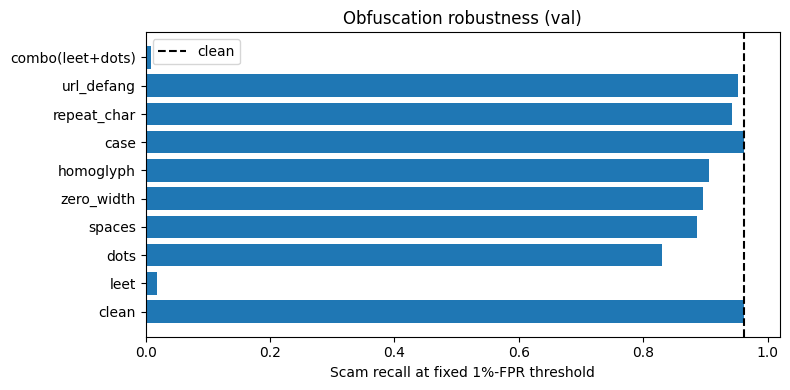

In [32]:
rng = random.Random(SEED)
WORD4 = re.compile(r"[A-Za-z]{4,}")

def atk_leet(t):
    m = {"a": "@", "e": "3", "i": "1", "o": "0", "s": "$"}
    return "".join(m.get(c.lower(), c) if rng.random() < 0.7 else c for c in t)

def atk_dots(t):
    return WORD4.sub(lambda m: ".".join(m.group(0)) if rng.random() < 0.5 else m.group(0), t)

def atk_spaces(t):
    return WORD4.sub(lambda m: " ".join(m.group(0)) if rng.random() < 0.5 else m.group(0), t)

def atk_zerowidth(t):
    return WORD4.sub(lambda m: m.group(0)[:2] + "\u200b" + m.group(0)[2:] if rng.random() < 0.7 else m.group(0), t)

def atk_homoglyph(t):
    m = {"a": "\u0430", "e": "\u0435", "o": "\u043e", "c": "\u0441", "p": "\u0440"}
    return "".join(m.get(c.lower(), c) if rng.random() < 0.7 else c for c in t)

def atk_case(t):
    return "".join(c.upper() if rng.random() < 0.5 else c.lower() for c in t)

def atk_repeat(t):
    return WORD4.sub(lambda m: (lambda w, i: w[:i] + w[i] * 2 + w[i:])(m.group(0), rng.randrange(1, len(m.group(0)) - 1))
                     if rng.random() < 0.5 else m.group(0), t)

def atk_url(t):
    return re.sub(r"\S*(?:http|www|bit\.ly|wa\.me)\S*",
                  lambda m: m.group(0).replace("http", "hxxp").replace(".", "[.]"), t)

def atk_combo(t):
    return atk_dots(atk_leet(t))

attacks = {"clean": lambda t: t, "leet": atk_leet, "dots": atk_dots, "spaces": atk_spaces,
           "zero_width": atk_zerowidth, "homoglyph": atk_homoglyph, "case": atk_case,
           "repeat_char": atk_repeat, "url_defang": atk_url, "combo(leet+dots)": atk_combo}

# ---- attack test ----
val_spam = val.loc[val["label"] == 1, "text"].tolist()
val_ham  = val.loc[val["label"] == 0, "text"].tolist()

rows, attacked_spam = [], {}
for name, fn in attacks.items():
    rng = random.Random(SEED)
    sp = [fn(t) for t in val_spam]
    hm = [fn(t) for t in val_ham]
    attacked_spam[name] = sp
    rows.append({"attack": name,
                 "spam_recall": float((predict_texts(sp) > THR).mean()),
                 "ham_FPR": float((predict_texts(hm) > THR).mean())})

atk_table = pd.DataFrame(rows)
base = atk_table.loc[atk_table["attack"] == "clean", "spam_recall"].iloc[0]
atk_table["recall_drop"] = base - atk_table["spam_recall"]
display(atk_table.round(4))

plt.figure(figsize=(8, 4))
plt.barh(atk_table["attack"], atk_table["spam_recall"])
plt.axvline(base, color="k", ls="--", label="clean")
plt.xlabel("Scam recall at fixed 1%-FPR threshold"); plt.xlim(0, 1.02)
plt.legend(); plt.title("Obfuscation robustness (val)"); plt.tight_layout(); plt.show()

In [34]:
import unicodedata
from sklearn.model_selection import cross_val_predict, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

atk_v1 = atk_table.copy()
print("OK | v1 saved:", atk_v1.shape)

OK | v1 saved: (10, 4)


In [35]:
ZW = re.compile(r"[\u200b-\u200f\u2060\ufeff\u00ad]")
HOMO = {0x0430: "a", 0x0435: "e", 0x043e: "o", 0x0441: "c", 0x0440: "p", 0x0445: "x",
        0x0443: "y", 0x0456: "i", 0x0455: "s", 0x0458: "j",
        0x0410: "A", 0x0415: "E", 0x041e: "O", 0x0421: "C", 0x0420: "P",
        0x0425: "X", 0x0423: "Y", 0x0406: "I"}

SEP_RE = re.compile(r"(?<![a-z0-9])(?:[a-z@$][.\-_]){2,}[a-z@$](?![\w@$/])")
SPC_RE = re.compile(r"(?<![a-z0-9])(?:[a-z@$] ){3,}[a-z@$](?![\w@$/])")

def clean_raw(text):
    t = unicodedata.normalize("NFKC", str(text))
    t = ZW.sub("", t)
    return t.translate(HOMO)

print("OK |", repr(clean_raw("Upd\u0430te Cl\u200bick")))

OK | 'Update Click'


In [36]:
def normalize(text):
    t = clean_raw(text).lower()
    t = t.replace("hxxp", "http").replace("[.]", ".").replace("(.)", ".")
    t = SEP_RE.sub(lambda m: re.sub(r"[.\-_]", "", m.group(0)), t)
    t = SPC_RE.sub(lambda m: m.group(0).replace(" ", ""), t)
    t = URL_RE.sub(" urltoken ", t)
    t = PHONE_RE.sub(" phonetoken ", t)
    t = LONG_NUM.sub(" numtoken ", t)
    t = re.sub(r"[a-z0-9@$]+", _deleet, t)
    return re.sub(r"\s+", " ", t).strip()

def build_hand(d):
    return pd.DataFrame([hand_features(clean_raw(x)) for x in d["text"]])

print("OK")

OK


In [37]:
tests = ["K.Y.C u.p.d.a.t.e now",
         "b l o c k e d a/c",
         "Upd\u0430te your KYC",
         "Cl\u200bick hxxp://sbi-kyc[.]xyz",
         "Your OTP is 482913. Do not share."]
for s in tests:
    print(repr(normalize(s)))

'kyc update now'
'blocked a/c'
'update your kyc'
'click urltoken'
'your otp is numtoken . do not share.'


In [38]:
def train_bundle(df):
    df = df.reset_index(drop=True).copy()
    df["norm"] = df["text"].map(normalize)
    H = build_hand(df)

    cv_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                          sublinear_tf=True, max_features=150000)
    wv_ = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                          max_features=50000, token_pattern=r"[^\s.,!?;:()\"']+")
    sc_ = StandardScaler()

    C = cv_.fit_transform(df["norm"])
    W = wv_.fit_transform(df["norm"])
    X = hstack([C, W, csr_matrix(sc_.fit_transform(H))]).tocsr()
    y = df["label"].values
    nt = C.shape[1] + W.shape[1]

    ests = {}
    for n in names:
        e = clone(tuned[n])
        if n == "NB-SVM":
            e.set_params(n_text=nt)
        ests[n] = e

    sp = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
              .split(X, y, df["group"]))

    Z = np.zeros((len(y), len(names)))
    for j, n in enumerate(names):
        for tr, te in sp:
            Z[te, j] = raw_score(clone(ests[n]).fit(X[tr], y[tr]), X[te])
        print("  OOF", n, "done")

    fit_ = {n: clone(ests[n]).fit(X, y) for n in names}
    meta_ = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(Z, y)
    oof_m = cross_val_predict(meta_, Z, y, cv=sp, method="decision_function")
    platt_ = LogisticRegression(C=1e6, max_iter=1000).fit(oof_m.reshape(-1, 1), y)
    p_oof_ = platt_.predict_proba(oof_m.reshape(-1, 1))[:, 1]
    thr_ = thr_for_fpr(y, p_oof_, 0.01)

    print("  threshold:", round(float(thr_), 5), "| train rows:", len(y), "| features:", X.shape[1])
    return dict(cv=cv_, wv=wv_, sc=sc_, fit=fit_, meta=meta_, platt=platt_, thr=thr_)

print("OK | train_bundle defined")

OK | train_bundle defined


In [39]:
def predict_bundle(B, texts):
    d = pd.DataFrame({"text": [str(t) for t in texts]})
    d["norm"] = d["text"].map(normalize)
    X = hstack([B["cv"].transform(d["norm"]),
                B["wv"].transform(d["norm"]),
                csr_matrix(B["sc"].transform(build_hand(d)))]).tocsr()
    Z = np.column_stack([raw_score(B["fit"][n], X) for n in names])
    s = B["meta"].decision_function(Z)
    return B["platt"].predict_proba(s.reshape(-1, 1))[:, 1]

# dependency check
needed = ["tuned", "names", "raw_score", "thr_for_fpr", "hand_features", "URL_RE",
          "PHONE_RE", "LONG_NUM", "_deleet", "train", "val", "test"]
missing = [v for v in needed if v not in globals()]
print("OK | predict_bundle defined | missing dependencies:", missing)

OK | predict_bundle defined | missing dependencies: []


In [40]:
def atk_dashes(t):
    return WORD4.sub(lambda m: "-".join(m.group(0)) if rng.random() < 0.5 else m.group(0), t)

eval_attacks = dict(attacks)
eval_attacks["dashes (unseen)"] = atk_dashes

print("OK | attacks:", list(eval_attacks.keys()))

OK | attacks: ['clean', 'leet', 'dots', 'spaces', 'zero_width', 'homoglyph', 'case', 'repeat_char', 'url_defang', 'combo(leet+dots)', 'dashes (unseen)']


In [41]:
def attack_table_for(B, tag):
    global rng
    rows = []
    for name, fn in eval_attacks.items():
        rng = random.Random(SEED)
        sp = [fn(t) for t in val_spam]
        hm = [fn(t) for t in val_ham]
        rows.append({"attack": name,
                     f"{tag}_recall": float((predict_bundle(B, sp) > B["thr"]).mean()),
                     f"{tag}_FPR": float((predict_bundle(B, hm) > B["thr"]).mean())})
    return pd.DataFrame(rows)

print("OK | eval ready | val spam:", len(val_spam), "| val ham:", len(val_ham))

OK | eval ready | val spam: 106 | val ham: 661


In [42]:
base_cols = ["text", "label", "group", "source"]
BA = train_bundle(train[base_cols])
tabA = attack_table_for(BA, "A")
display(tabA.round(4))

  OOF LogReg done
  OOF LinearSVC done
  OOF NB-SVM done
  OOF SGD done
  OOF LightGBM done
  threshold: 0.28106 | train rows: 3797 | features: 38418


,attack,A_recall,A_FPR
0,clean,0.9623,0.0061
1,leet,0.9528,0.0454
2,dots,0.9434,0.0030
3,spaces,0.9528,0.0061
4,zero_width,0.9623,0.0061
5,homoglyph,0.9623,0.0061
6,case,0.9717,0.0061
7,repeat_char,0.9528,0.0045
8,url_defang,0.9623,0.0061
9,combo(leet+dots),0.9717,0.0530


In [43]:
rng = random.Random(SEED + 1)        # test attack seed (SEED) la irundhu veru
aug_fns = [atk_leet, atk_dots, atk_spaces, atk_zerowidth, atk_homoglyph,
           atk_case, atk_repeat, atk_url, atk_combo]

aug = train[base_cols].copy()
aug["text"] = [rng.choice(aug_fns)(t) for t in aug["text"]]
aug["source"] = aug["source"] + "_aug"
train_aug = pd.concat([train[base_cols], aug], ignore_index=True)

print("OK | train_aug:", train_aug.shape, "| scam rate:", round(train_aug.label.mean(), 3))
print(aug.sample(3, random_state=SEED)["text"].tolist())

OK | train_aug: (7594, 4) | scam rate: 0.119
["OK i'm waliking ard now... Do u wan me 2 buy anything go ur house?", 'Hmmm.. Thk sure gоt timе tо hор ard... Ya, can gо 4 frее аbt... Muz сall u tо discuss liaо... ', 'You kn\u200bow my old Dom I to\u200bld you about ye\u200bsterday ? His na\u200bme is Ro\u200bger? He got in to\u200buch wi\u200bth me la\u200bst night and wa\u200bnts me to meet him today at 2 pm']


In [44]:
BB = train_bundle(train_aug)
tabB = attack_table_for(BB, "B")
display(tabB.round(4))

  OOF LogReg done
  OOF LinearSVC done
  OOF NB-SVM done
  OOF SGD done
  OOF LightGBM done
  threshold: 0.23244 | train rows: 7594 | features: 98514


,attack,B_recall,B_FPR
0,clean,0.9434,0.0091
1,leet,0.9434,0.0061
2,dots,0.9151,0.0076
3,spaces,0.9245,0.0091
4,zero_width,0.9434,0.0091
5,homoglyph,0.9434,0.0091
6,case,0.9434,0.0091
7,repeat_char,0.9245,0.0076
8,url_defang,0.9434,0.0091
9,combo(leet+dots),0.9340,0.0136


,attack,v1_recall,A_recall,B_recall,v1_FPR,A_FPR,B_FPR
0,clean,0.9623,0.9623,0.9434,0.0121,0.0061,0.0091
1,leet,0.0189,0.9528,0.9434,0.0000,0.0454,0.0061
2,dots,0.8302,0.9434,0.9151,0.0015,0.0030,0.0076
3,spaces,0.8868,0.9528,0.9245,0.0045,0.0061,0.0091
4,zero_width,0.8962,0.9623,0.9434,0.0061,0.0061,0.0091
5,homoglyph,0.9057,0.9623,0.9434,0.0091,0.0061,0.0091
6,case,0.9623,0.9717,0.9434,0.0076,0.0061,0.0091
7,repeat_char,0.9434,0.9528,0.9245,0.0091,0.0045,0.0076
8,url_defang,0.9528,0.9623,0.9434,0.0121,0.0061,0.0091
9,combo(leet+dots),0.0094,0.9717,0.9340,0.0000,0.0530,0.0136


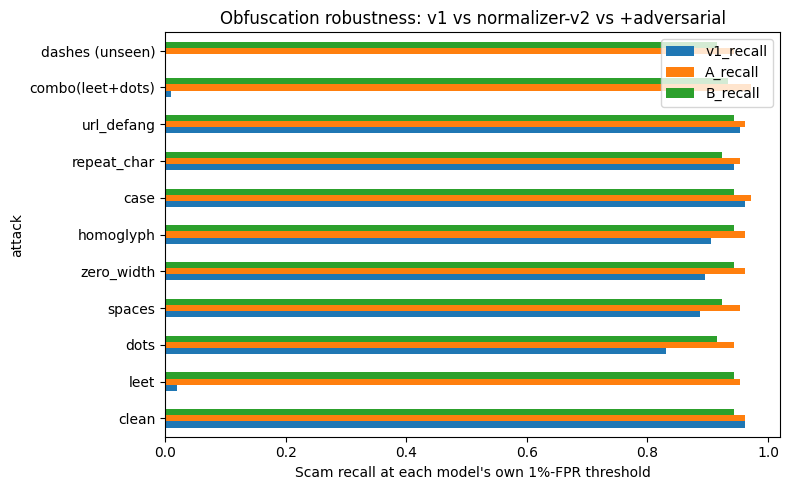

In [45]:
v1 = atk_v1[["attack", "spam_recall", "ham_FPR"]].rename(
    columns={"spam_recall": "v1_recall", "ham_FPR": "v1_FPR"})
cmp_ = (tabA.merge(tabB, on="attack").merge(v1, on="attack", how="left")
        [["attack", "v1_recall", "A_recall", "B_recall", "v1_FPR", "A_FPR", "B_FPR"]])
display(cmp_.round(4))

ax = cmp_.set_index("attack")[["v1_recall", "A_recall", "B_recall"]].plot.barh(figsize=(8, 5))
ax.set_xlim(0, 1.02)
ax.set_xlabel("Scam recall at each model's own 1%-FPR threshold")
plt.title("Obfuscation robustness: v1 vs normalizer-v2 vs +adversarial")
plt.tight_layout(); plt.show()

In [46]:
FINAL = BB            # BA venum na inga maathu
p_val_f = predict_bundle(FINAL, val["text"])
val_e = val.assign(p=p_val_f, pred=(p_val_f > FINAL["thr"]).astype(int))

fn = val_e[(val_e.label == 1) & (val_e.pred == 0)]
fp = val_e[(val_e.label == 0) & (val_e.pred == 1)]
print("OK | threshold:", round(float(FINAL["thr"]), 5))
print("Scam missed (FN):", len(fn), "of", int((val_e.label == 1).sum()))
print("Legit blocked (FP):", len(fp), "of", int((val_e.label == 0).sum()))

OK | threshold: 0.23244
Scam missed (FN): 6 of 106
Legit blocked (FP): 6 of 661


In [47]:
rows = []
for s, g in val_e.groupby("source"):
    sp, hm = g[g.label == 1], g[g.label == 0]
    rows.append({"source": s, "n": len(g),
                 "scam_n": len(sp), "recall": (sp.pred == 1).mean() if len(sp) else np.nan,
                 "ham_n": len(hm), "FPR": (hm.pred == 1).mean() if len(hm) else np.nan})
display(pd.DataFrame(rows).round(4))

,source,n,scam_n,recall,ham_n,FPR
0,synthetic,36,4,1.0000,32,0.0000
1,uci,731,102,0.9412,629,0.0095


In [48]:
print("=== MISSED SCAMS (lowest score first) ===")
for r in fn.sort_values("p").head(10).itertuples():
    print(f"p={r.p:.3f} [{r.source}] {r.text[:110]}")

print("\n=== LEGIT BLOCKED (highest score first) ===")
for r in fp.sort_values("p", ascending=False).head(10).itertuples():
    print(f"p={r.p:.3f} [{r.source}] {r.text[:110]}")

=== MISSED SCAMS (lowest score first) ===
p=0.011 [uci] Hello darling how are you today? I would love to have a chat, why dont you tell me what you look like and what
p=0.025 [uci] Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?
p=0.037 [uci] For sale - arsenal dartboard. Good condition but no doubles or trebles!
p=0.116 [uci] Adult 18 Content Your video will be with you shortly
p=0.142 [uci] 3. You have received your mobile content. Enjoy
p=0.199 [uci] SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychi

=== LEGIT BLOCKED (highest score first) ===
p=0.721 [uci] Sorry to trouble u again. Can buy 4d for my dad again? 1405, 1680, 1843. All 2 big 1 small, sat n sun. Thanx.
p=0.518 [uci] I take it the post has come then! You must have 1000s of texts now! Happy reading. My one from wiv hello carol
p=0.504 [uci] Actually i deleted my old website..now i m blogging at magicalsongs.

In [49]:
lr_f = FINAL["fit"]["LogReg"]
n_char = len(FINAL["cv"].vocabulary_)
n_word = len(FINAL["wv"].vocabulary_)

w_names = FINAL["wv"].get_feature_names_out()
w_coef = lr_f.coef_.ravel()[n_char:n_char + n_word]
order = np.argsort(w_coef)

print("TOP SCAM indicators:")
print([ (w_names[i], round(float(w_coef[i]), 2)) for i in order[::-1][:20] ])
print("\nTOP LEGIT indicators:")
print([ (w_names[i], round(float(w_coef[i]), 2)) for i in order[:20] ])

TOP SCAM indicators:
[('numtoken', 5.27), ('free', 3.28), ('reply', 3.0), ('text', 2.84), ('to', 2.68), ('&', 2.61), ('to numtoken', 2.58), ('a', 2.5), ('txt', 2.4), ('your', 2.22), ('mobile', 2.13), ('tones', 2.05), ('ringtone', 1.99), ('order', 1.95), ('your mobile', 1.91), ('service', 1.87), ('now', 1.86), ('this', 1.77), ('ltd', 1.75), ('new', 1.66)]

TOP LEGIT indicators:
[('i', -3.74), ('my', -2.69), ('me', -2.32), ('&lt', -2.19), ('&lt #&gt', -2.03), ('#&gt', -2.03), ('but', -2.01), ('1', -1.87), ('was', -1.65), ('t0 @/c', -1.62), ('@/c', -1.62), ('@/c xx', -1.62), ('credited t0', -1.58), ('that', -1.55), ('r$', -1.48), ('00 credited', -1.46), ('xx numtoken', -1.46), ('m3', -1.45), ('when', -1.37), ('in', -1.36)]


In [50]:
hand_cols = list(build_hand(val.head(2)).columns)
h_coef = lr_f.coef_.ravel()[n_char + n_word:]
print(pd.Series(h_coef, index=hand_cols).sort_values().round(3).to_string())

has_otp            -2.836
has_do_not_share   -1.712
punct_ratio        -0.544
has_txn_words      -0.487
n_words            -0.345
leet_hits          -0.132
tamil_ratio         0.000
n_rs                0.022
upper_ratio         0.197
n_excl              0.399
n_urls              0.590
urgent_hits         0.694
has_shortener       0.822
n_phones            0.869
len                 1.026
has_sus_tld         1.113
digit_ratio         1.303


In [51]:
rng = random.Random(SEED + 1)
aug_fns_ho = [atk_leet, atk_dots, atk_zerowidth, atk_homoglyph, atk_case, atk_url, atk_combo]

aug_ho = train[base_cols].copy()
aug_ho["text"] = [rng.choice(aug_fns_ho)(t) for t in aug_ho["text"]]
aug_ho["source"] = aug_ho["source"] + "_aug"
train_ho = pd.concat([train[base_cols], aug_ho], ignore_index=True)
print("OK | train_ho:", train_ho.shape)

OK | train_ho: (7594, 4)


In [52]:
BH = train_bundle(train_ho)
tabH = attack_table_for(BH, "H")
display(tabH.round(4))

  OOF LogReg done
  OOF LinearSVC done
  OOF NB-SVM done
  OOF SGD done
  OOF LightGBM done
  threshold: 0.37717 | train rows: 7594 | features: 98652


,attack,H_recall,H_FPR
0,clean,0.9151,0.0045
1,leet,0.8962,0.0045
2,dots,0.9057,0.0045
3,spaces,0.8962,0.0030
4,zero_width,0.9151,0.0045
5,homoglyph,0.9151,0.0045
6,case,0.9057,0.0045
7,repeat_char,0.8962,0.0045
8,url_defang,0.9151,0.0045
9,combo(leet+dots),0.8962,0.0045


In [53]:
cmp2 = (tabA.merge(tabB, on="attack").merge(tabH, on="attack")
        [["attack", "A_recall", "B_recall", "H_recall", "A_FPR", "B_FPR", "H_FPR"]])
display(cmp2.round(4))
display(cmp2[cmp2.attack.isin(["spaces", "repeat_char"])].round(4))

,attack,A_recall,B_recall,H_recall,A_FPR,B_FPR,H_FPR
0,clean,0.9623,0.9434,0.9151,0.0061,0.0091,0.0045
1,leet,0.9528,0.9434,0.8962,0.0454,0.0061,0.0045
2,dots,0.9434,0.9151,0.9057,0.0030,0.0076,0.0045
3,spaces,0.9528,0.9245,0.8962,0.0061,0.0091,0.0030
4,zero_width,0.9623,0.9434,0.9151,0.0061,0.0091,0.0045
5,homoglyph,0.9623,0.9434,0.9151,0.0061,0.0091,0.0045
6,case,0.9717,0.9434,0.9057,0.0061,0.0091,0.0045
7,repeat_char,0.9528,0.9245,0.8962,0.0045,0.0076,0.0045
8,url_defang,0.9623,0.9434,0.9151,0.0061,0.0091,0.0045
9,combo(leet+dots),0.9717,0.9340,0.8962,0.0530,0.0136,0.0045


,attack,A_recall,B_recall,H_recall,A_FPR,B_FPR,H_FPR
3,spaces,0.9528,0.9245,0.8962,0.0061,0.0091,0.0030
7,repeat_char,0.9528,0.9245,0.8962,0.0045,0.0076,0.0045


In [54]:
FINAL = BB     # val paathu decide pannadhu. Test paatha apram maathaadha

p_test = predict_bundle(FINAL, test["text"])
y_t = test["label"].values
THR_F = float(FINAL["thr"])
pred_t = (p_test > THR_F).astype(int)

print("OK | threshold:", round(THR_F, 5), "| test rows:", len(test),
      "| scam:", int(y_t.sum()), "| legit:", int((y_t == 0).sum()))

OK | threshold: 0.23244 | test rows: 745 | scam: 113 | legit: 632


In [55]:
from sklearn.metrics import matthews_corrcoef

r = eval_at(y_t, p_test, THR_F)
head = {"ROC-AUC": roc_auc_score(y_t, p_test),
        "PR-AUC": average_precision_score(y_t, p_test),
        "MCC": matthews_corrcoef(y_t, pred_t), **r}
display(pd.Series(head).round(4).to_frame("TEST (all sources)"))

,TEST (all sources)
ROC-AUC,0.9986
PR-AUC,0.9937
MCC,0.9690
recall,0.9823
FPR,0.0063
precision,0.9652
TP,111.0000
FP,4.0000
FN,2.0000
TN,628.0000


In [56]:
rb = np.random.default_rng(SEED)
pos, neg = np.where(y_t == 1)[0], np.where(y_t == 0)[0]
B_ = {"recall": [], "FPR": [], "precision": [], "PR-AUC": [], "ROC-AUC": []}

for _ in range(1000):
    idx = np.concatenate([rb.choice(pos, len(pos)), rb.choice(neg, len(neg))])
    yy, pp, dd = y_t[idx], p_test[idx], pred_t[idx]
    tp = int(((dd == 1) & (yy == 1)).sum()); fp_ = int(((dd == 1) & (yy == 0)).sum())
    B_["recall"].append(tp / max((yy == 1).sum(), 1))
    B_["FPR"].append(fp_ / max((yy == 0).sum(), 1))
    B_["precision"].append(tp / max(tp + fp_, 1))
    B_["PR-AUC"].append(average_precision_score(yy, pp))
    B_["ROC-AUC"].append(roc_auc_score(yy, pp))

ci = pd.DataFrame({k: [np.percentile(v, 2.5), np.mean(v), np.percentile(v, 97.5)]
                   for k, v in B_.items()}, index=["2.5%", "mean", "97.5%"]).T
display(ci.round(4))

,2.5%,mean,97.5%
recall,0.9558,0.9825,1.0000
FPR,0.0016,0.0064,0.0127
precision,0.9322,0.9650,0.9912
PR-AUC,0.9859,0.9937,0.9992
ROC-AUC,0.9967,0.9986,0.9998


In [57]:
from scipy.stats import beta

def cp(k, n, a=0.05):
    if n == 0: return (np.nan, np.nan)
    lo = 0.0 if k == 0 else beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

te = test.assign(p=p_test, pred=pred_t)
rows = []
for s, g in te.groupby("source"):
    sp, hm = g[g.label == 1], g[g.label == 0]
    k1, n1 = int((sp.pred == 1).sum()), len(sp)
    k0, n0 = int((hm.pred == 1).sum()), len(hm)
    l1, h1 = cp(k1, n1); l0, h0 = cp(k0, n0)
    rows.append({"source": s, "scam_n": n1, "recall": k1 / max(n1, 1),
                 "recall_CI": f"{l1:.2f}-{h1:.2f}",
                 "legit_n": n0, "FPR": k0 / max(n0, 1), "FPR_CI": f"{l0:.2f}-{h0:.2f}"})
display(pd.DataFrame(rows).round(4))
print("own_real in test:", int((test.source == "own_real").sum()))

,source,scam_n,recall,recall_CI,legit_n,FPR,FPR_CI
0,own_real,1,1.000,0.03-1.00,0,0.0000,nan-nan
1,synthetic,7,1.000,0.59-1.00,6,0.0000,0.00-0.46
2,uci,105,0.981,0.93-1.00,626,0.0064,0.00-0.02


own_real in test: 1


In [58]:
ts_spam = test.loc[test.label == 1, "text"].tolist()
ts_ham = test.loc[test.label == 0, "text"].tolist()

rows = []
for name, fn_ in eval_attacks.items():
    rng = random.Random(SEED)
    sp = [fn_(t) for t in ts_spam]
    hm = [fn_(t) for t in ts_ham]
    rows.append({"attack": name,
                 "recall": float((predict_bundle(FINAL, sp) > THR_F).mean()),
                 "FPR": float((predict_bundle(FINAL, hm) > THR_F).mean())})
tab_test_atk = pd.DataFrame(rows)
tab_test_atk["drop_vs_clean"] = tab_test_atk.loc[0, "recall"] - tab_test_atk["recall"]
display(tab_test_atk.round(4))

,attack,recall,FPR,drop_vs_clean
0,clean,0.9823,0.0063,0.0000
1,leet,0.9823,0.0095,0.0000
2,dots,0.9823,0.0063,0.0000
3,spaces,0.9823,0.0063,0.0000
4,zero_width,0.9823,0.0063,0.0000
5,homoglyph,0.9823,0.0063,0.0000
6,case,0.9823,0.0063,0.0000
7,repeat_char,0.9735,0.0063,0.0088
8,url_defang,0.9823,0.0063,0.0000
9,combo(leet+dots),0.9823,0.0095,0.0000


In [59]:
import json
out = {"threshold": THR_F, "headline": {k: float(v) for k, v in head.items()},
       "ci_95": ci.round(4).to_dict(), "attacks": tab_test_atk.round(4).to_dict("records")}
with open("data/test_results.json", "w") as f:
    json.dump(out, f, indent=2)
print("OK | saved data/test_results.json")

OK | saved data/test_results.json


In [60]:
%%writefile scam_detector.py
import re, unicodedata
import numpy as np
import pandas as pd
import joblib
from scipy.sparse import hstack, csr_matrix
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression

URL_RE = re.compile(r"(https?://\S+|www\.\S+|\b[\w-]+\.(?:xyz|top|in|com|co|ly|link|site|online|club|info)\S*|\bbit\.ly/\S+|\bwa\.me/\S+)")
PHONE_RE = re.compile(r"(?<!\d)(?:\+?91[\s-]?)?[6-9][\dXx]{9}(?!\d)")
LONG_NUM = re.compile(r"\d{4,}")
LEET = str.maketrans({"0": "o", "1": "i", "3": "e", "4": "a", "5": "s", "7": "t", "@": "a", "$": "s"})

ZW = re.compile(r"[\u200b-\u200f\u2060\ufeff\u00ad]")
HOMO = {0x0430: "a", 0x0435: "e", 0x043e: "o", 0x0441: "c", 0x0440: "p", 0x0445: "x",
        0x0443: "y", 0x0456: "i", 0x0455: "s", 0x0458: "j",
        0x0410: "A", 0x0415: "E", 0x041e: "O", 0x0421: "C", 0x0420: "P",
        0x0425: "X", 0x0423: "Y", 0x0406: "I"}
SEP_RE = re.compile(r"(?<![a-z0-9])(?:[a-z@$][.\-_]){2,}[a-z@$](?![\w@$/])")
SPC_RE = re.compile(r"(?<![a-z0-9])(?:[a-z@$] ){3,}[a-z@$](?![\w@$/])")

SHORTENERS = ["bit.ly", "tinyurl", "t.co", "goo.gl", "wa.me", "cutt.ly", "rb.gy"]
SUS_TLD = [".xyz", ".top", ".online", ".club", ".site", ".link", ".info"]
URGENT = ["urgent", "immediately", "today", "expire", "block", "suspend", "freez", "deactivat",
          "within 24", "last chance", "udane", "verify", "kyc", "aadhaar", "pan card", "claim",
          "prize", "won", "lottery", "winner", "congrat", "refund", "loan", "earn", "click",
          "pending", "penalty", "legal", "parisu", "install"]
RS_RE = re.compile(r"(?:rs\.?|inr|₹)\s*[\d,]+")


def _deleet(m):
    t = m.group(0)
    if len(re.findall(r"[a-z]", t)) >= 3 and re.search(r"[0-9@$]", t):
        return t.translate(LEET)
    return t


def clean_raw(text):
    t = unicodedata.normalize("NFKC", str(text))
    t = ZW.sub("", t)
    return t.translate(HOMO)


def normalize(text):
    t = clean_raw(text).lower()
    t = t.replace("hxxp", "http").replace("[.]", ".").replace("(.)", ".")
    t = SEP_RE.sub(lambda m: re.sub(r"[.\-_]", "", m.group(0)), t)
    t = SPC_RE.sub(lambda m: m.group(0).replace(" ", ""), t)
    t = URL_RE.sub(" urltoken ", t)
    t = PHONE_RE.sub(" phonetoken ", t)
    t = LONG_NUM.sub(" numtoken ", t)
    t = re.sub(r"[a-z0-9@$]+", _deleet, t)
    return re.sub(r"\s+", " ", t).strip()


def hand_features(raw):
    t = str(raw)
    low = t.lower()
    n = max(len(t), 1)
    words = low.split()
    urls = URL_RE.findall(low)
    return {
        "len": len(t),
        "n_words": len(words),
        "digit_ratio": sum(c.isdigit() for c in t) / n,
        "upper_ratio": sum(c.isupper() for c in t) / n,
        "punct_ratio": sum((not c.isalnum()) and (not c.isspace()) for c in t) / n,
        "n_excl": t.count("!"),
        "n_urls": len(urls),
        "has_shortener": int(any(s in low for s in SHORTENERS)),
        "has_sus_tld": int(any(s in low for s in SUS_TLD)),
        "n_phones": len(PHONE_RE.findall(t)),
        "n_rs": len(RS_RE.findall(low)),
        "urgent_hits": sum(k in low for k in URGENT),
        "tamil_ratio": sum("\u0b80" <= c <= "\u0bff" for c in t) / n,
        "has_otp": int("otp" in low),
        "has_do_not_share": int("do not share" in low or "don't share" in low),
        "has_txn_words": int(any(k in low for k in ["debited", "credited", "upi ref", "a/c xx"])),
        "leet_hits": len(re.findall(r"[a-z]+[0@$][a-z]+", low)),
    }


def build_hand(d):
    return pd.DataFrame([hand_features(clean_raw(x)) for x in d["text"]])


class NBSVM(BaseEstimator, ClassifierMixin):
    def __init__(self, n_text=0, C=4.0, alpha=1.0):
        self.n_text = n_text
        self.C = C
        self.alpha = alpha

    def decision_function(self, X):
        return self.lr_.decision_function(X[:, :self.n_text].multiply(self.r_).tocsr())


def raw_score(m, X):
    if hasattr(m, "decision_function"):
        return m.decision_function(X)
    p = np.clip(m.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def load(path="scam_model.joblib"):
    return joblib.load(path)


def predict_proba(B, texts):
    d = pd.DataFrame({"text": [str(t) for t in texts]})
    d["norm"] = d["text"].map(normalize)
    X = hstack([B["cv"].transform(d["norm"]),
                B["wv"].transform(d["norm"]),
                csr_matrix(B["sc"].transform(build_hand(d)))]).tocsr()
    Z = np.column_stack([raw_score(B["fit"][n], X) for n in B["names"]])
    s = B["meta"].decision_function(Z)
    return B["platt"].predict_proba(s.reshape(-1, 1))[:, 1]


def predict(B, texts):
    p = predict_proba(B, texts)
    return [{"scam_probability": float(x), "is_scam": bool(x > B["thr"])} for x in p]

Writing scam_detector.py


In [61]:
import importlib, joblib
import scam_detector as sd
importlib.reload(sd)

fit_new = {}
for n, m in FINAL["fit"].items():
    if n == "NB-SVM":
        o = sd.NBSVM(n_text=m.n_text, C=m.C, alpha=m.alpha)
        o.r_, o.lr_, o.classes_ = m.r_, m.lr_, m.classes_
        fit_new[n] = o
    else:
        fit_new[n] = m

SAVE = {**FINAL, "fit": fit_new, "names": list(names), "thr": float(FINAL["thr"])}
joblib.dump(SAVE, "scam_model.joblib", compress=3)

import os
print("OK | size MB:", round(os.path.getsize("scam_model.joblib") / 1e6, 2))

OK | size MB: 4.01


In [62]:
B2 = sd.load("scam_model.joblib")
p_mod = sd.predict_proba(B2, val["text"])
p_nb = predict_bundle(FINAL, val["text"])

print("Matches notebook:", np.allclose(p_mod, p_nb, atol=1e-6))
print("Max diff:", float(np.abs(p_mod - p_nb).max()))

demo = ["Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi-kyc-update.xyz",
        "Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank",
        "Machi, naalaiku evening 6 mani ku meet pannalam, ok va?",
        "Ungal account block aagapogudhu, udane click pannunga bit.ly/x1y2"]
for t, r in zip(demo, sd.predict(B2, demo)):
    print(f"{r['scam_probability']:.4f}  {'SCAM' if r['is_scam'] else 'ok  '}  {t[:70]}")

Matches notebook: True
Max diff: 0.0
0.9935  SCAM  Dear customer your SBI a/c will be blocked today. Update KYC now http:
0.0000  ok    Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank
0.0040  ok    Machi, naalaiku evening 6 mani ku meet pannalam, ok va?
0.9792  SCAM  Ungal account block aagapogudhu, udane click pannunga bit.ly/x1y2


In [63]:
import sklearn, lightgbm, scipy
print(f"scikit-learn=={sklearn.__version__}")
print(f"lightgbm=={lightgbm.__version__}")
print(f"scipy=={scipy.__version__}")
print(f"numpy=={np.__version__}")
print(f"pandas=={pd.__version__}")
print(f"joblib=={joblib.__version__}")

scikit-learn==1.6.1
lightgbm==4.6.0
scipy==1.16.3
numpy==2.1.3
pandas==2.2.3
joblib==1.6.0


In [64]:
%%writefile app.py
import streamlit as st
import scam_detector as sd

st.set_page_config(page_title="Scam SMS Detector", page_icon="🛡️")

@st.cache_resource
def get_model():
    return sd.load("scam_model.joblib")

B = get_model()

st.title("🛡️ Scam SMS Detector (Tamil / Tanglish / English)")
st.caption("Classical ML: char+word TF-IDF + handcrafted features, stacked ensemble. "
           "Message server la store aagaadhu.")

EXAMPLES = {
    "Fake KYC": "Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi-kyc-update.xyz",
    "Tanglish scam": "Ungal account block aagapogudhu, udane click pannunga bit.ly/x1y2",
    "Obfuscated": "Ur a/c bl0cked. K.Y.C upd@te now hxxp://sbi-kyc[.]xyz",
    "Bank OTP (legit)": "Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank",
    "Friend chat (legit)": "Machi, naalaiku evening 6 mani ku meet pannalam, ok va?",
}
choice = st.selectbox("Example", ["(type my own)"] + list(EXAMPLES))
default = EXAMPLES.get(choice, "")
text = st.text_area("Message", value=default, height=120)

if st.button("Check") and text.strip():
    r = sd.predict(B, [text])[0]
    p = r["scam_probability"]
    if r["is_scam"]:
        st.error(f"⚠️ Likely SCAM  (score {p:.3f})")
    else:
        st.success(f"✅ Looks OK  (score {p:.3f})")
    st.progress(min(max(p, 0.0), 1.0))
    st.caption(f"Decision threshold {B['thr']:.4f} (set for ~1% false positives on legit messages).")
    st.info("Idhu oru ML estimate. Bank / OTP message-a ithai mattum nambi block pannaadhinga.")

Writing app.py


In [65]:
%%writefile requirements.txt
streamlit
scikit-learn==X.Y.Z
lightgbm==X.Y.Z
scipy==X.Y.Z
numpy==X.Y.Z
pandas==X.Y.Z
joblib==X.Y.Z

Writing requirements.txt


In [66]:
import os, shutil
from google.colab import files

os.makedirs("deploy", exist_ok=True)
for f in ["app.py", "scam_detector.py", "scam_model.joblib", "requirements.txt"]:
    shutil.copy(f, "deploy/" + f)
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
print("FINAL threshold:", round(float(FINAL["thr"]), 5))

# 1. Train / val / test overlap check
for a_name, a in [("train", train), ("val", val)]:
    print(f"{a_name} vs test  text overlap:", len(set(a["norm"]) & set(test["norm"])),
          "| group overlap:", len(set(a["group"]) & set(test["group"])))

# 2. Class balance
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s} rows={len(d)} scam_rate={d.label.mean():.3f}")

# 3. Real data count
print("own_real  train/val/test:",
      int((train.source == "own_real").sum()),
      int((val.source == "own_real").sum()),
      int((test.source == "own_real").sum()))

FINAL threshold: 0.23244
train vs test  text overlap: 0 | group overlap: 0
val vs test  text overlap: 0 | group overlap: 0
train rows=3797 scam_rate=0.119
val   rows=767 scam_rate=0.138
test  rows=745 scam_rate=0.152
own_real  train/val/test: 3 0 1


In [68]:
B2 = sd.load("scam_model.joblib")
p_mod = sd.predict_proba(B2, val["text"])
p_nb = predict_bundle(FINAL, val["text"])
print("Matches notebook:", np.allclose(p_mod, p_nb, atol=1e-6))

Matches notebook: True


In [69]:
from sklearn.metrics import matthews_corrcoef, roc_auc_score, average_precision_score

p_test = predict_bundle(FINAL, test["text"])
y_t = test["label"].values
THR_F = float(FINAL["thr"])
pred_t = (p_test > THR_F).astype(int)

r = eval_at(y_t, p_test, THR_F)
head = {"ROC-AUC": roc_auc_score(y_t, p_test),
        "PR-AUC": average_precision_score(y_t, p_test),
        "MCC": matthews_corrcoef(y_t, pred_t), **r}
display(pd.Series(head).round(4).to_frame("TEST (all sources)"))

,TEST (all sources)
ROC-AUC,0.9986
PR-AUC,0.9937
MCC,0.9690
recall,0.9823
FPR,0.0063
precision,0.9652
TP,111.0000
FP,4.0000
FN,2.0000
TN,628.0000


In [70]:
rb = np.random.default_rng(SEED)
pos, neg = np.where(y_t == 1)[0], np.where(y_t == 0)[0]
B_ = {"recall": [], "FPR": [], "precision": [], "PR-AUC": [], "ROC-AUC": []}

for _ in range(1000):
    idx = np.concatenate([rb.choice(pos, len(pos)), rb.choice(neg, len(neg))])
    yy, pp, dd = y_t[idx], p_test[idx], pred_t[idx]
    tp = int(((dd == 1) & (yy == 1)).sum()); fp_ = int(((dd == 1) & (yy == 0)).sum())
    B_["recall"].append(tp / max((yy == 1).sum(), 1))
    B_["FPR"].append(fp_ / max((yy == 0).sum(), 1))
    B_["precision"].append(tp / max(tp + fp_, 1))
    B_["PR-AUC"].append(average_precision_score(yy, pp))
    B_["ROC-AUC"].append(roc_auc_score(yy, pp))

ci = pd.DataFrame({k: [np.percentile(v, 2.5), np.mean(v), np.percentile(v, 97.5)]
                   for k, v in B_.items()}, index=["2.5%", "mean", "97.5%"]).T
display(ci.round(4))

,2.5%,mean,97.5%
recall,0.9558,0.9825,1.0000
FPR,0.0016,0.0064,0.0127
precision,0.9322,0.9650,0.9912
PR-AUC,0.9859,0.9937,0.9992
ROC-AUC,0.9967,0.9986,0.9998


In [71]:
from scipy.stats import beta

def cp(k, n, a=0.05):
    if n == 0: return (np.nan, np.nan)
    lo = 0.0 if k == 0 else beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

te = test.assign(p=p_test, pred=pred_t)
rows = []
for s, g in te.groupby("source"):
    sp, hm = g[g.label == 1], g[g.label == 0]
    k1, n1 = int((sp.pred == 1).sum()), len(sp)
    k0, n0 = int((hm.pred == 1).sum()), len(hm)
    l1, h1 = cp(k1, n1); l0, h0 = cp(k0, n0)
    rows.append({"source": s, "scam_n": n1, "recall": k1 / max(n1, 1), "recall_CI": f"{l1:.2f}-{h1:.2f}",
                 "legit_n": n0, "FPR": k0 / max(n0, 1), "FPR_CI": f"{l0:.2f}-{h0:.2f}"})
display(pd.DataFrame(rows).round(4))

,source,scam_n,recall,recall_CI,legit_n,FPR,FPR_CI
0,own_real,1,1.000,0.03-1.00,0,0.0000,nan-nan
1,synthetic,7,1.000,0.59-1.00,6,0.0000,0.00-0.46
2,uci,105,0.981,0.93-1.00,626,0.0064,0.00-0.02


In [72]:
checks = {
    "ROC-AUC >= 0.98": head["ROC-AUC"] >= 0.98,
    "Recall >= 0.90": head["recall"] >= 0.90,
    "FPR <= 0.03": head["FPR"] <= 0.03,
    "Worst attack drop < 0.05": tab_test_atk["drop_vs_clean"].max() < 0.05,
    "Attack FPR <= 0.05": tab_test_atk["FPR"].max() <= 0.05,
}
for k, v in checks.items():
    print("PASS" if v else "WARN", "|", k)

n_real_test = int((test.source == "own_real").sum())
print("\nReal Indian messages in test:", n_real_test)
if n_real_test < 50:
    print("WARN | Real data romba kammi. 'Indian scam accuracy' nu claim pannaadheenga.")

PASS | ROC-AUC >= 0.98
PASS | Recall >= 0.90
PASS | FPR <= 0.03
PASS | Worst attack drop < 0.05
PASS | Attack FPR <= 0.05

Real Indian messages in test: 1
WARN | Real data romba kammi. 'Indian scam accuracy' nu claim pannaadheenga.


In [73]:
import scam_detector as sd
B2 = sd.load("scam_model.joblib")

my_msgs = [
    "Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi-kyc-update.xyz",
    "Ungal bank account block aagapogudhu, udane KYC update pannunga bit.ly/kyc-upd8",
    "Ur a/c bl0cked. K.Y.C upd@te now hxxp://sbi-kyc[.]xyz",
    "Congrats! You won Rs 25,00,000 in lottery. Call 9876543210 to claim",
    "Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank",
    "Rs 1,250.00 debited from A/c XX1234 on 05-Oct. UPI Ref 123456789. - SBI",
    "Machi, naalaiku evening 6 mani ku meet pannalam, ok va?",
    "Your order has been shipped and will arrive by Tuesday. Track in the Amazon app.",
]
print("threshold:", round(B2["thr"], 4), "\n")
for t, r in zip(my_msgs, sd.predict(B2, my_msgs)):
    tag = "SCAM" if r["is_scam"] else "ok  "
    print(f"{r['scam_probability']:.3f}  {tag}  {t[:75]}")

threshold: 0.2324 

0.994  SCAM  Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi
0.990  SCAM  Ungal bank account block aagapogudhu, udane KYC update pannunga bit.ly/kyc-
0.435  SCAM  Ur a/c bl0cked. K.Y.C upd@te now hxxp://sbi-kyc[.]xyz
0.998  SCAM  Congrats! You won Rs 25,00,000 in lottery. Call 9876543210 to claim
0.000  ok    Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank
0.092  ok    Rs 1,250.00 debited from A/c XX1234 on 05-Oct. UPI Ref 123456789. - SBI
0.004  ok    Machi, naalaiku evening 6 mani ku meet pannalam, ok va?
0.023  ok    Your order has been shipped and will arrive by Tuesday. Track in the Amazon


In [74]:
edge = ["", "   ", "a", "😀😀😀", "ஊங்கள் வங்கி கணக்கு முடக்கப்படும், உடனே KYC புதுப்பிக்கவும்",
        "A" * 5000, None, 12345]
for t in edge:
    try:
        r = sd.predict(B2, [t])[0]
        print("OK   ", f"{r['scam_probability']:.3f}", repr(str(t)[:40]))
    except Exception as e:
        print("FAIL ", repr(str(t)[:40]), "->", type(e).__name__, e)

OK    0.003 ''
OK    0.003 '   '
OK    0.007 'a'
OK    0.002 '😀😀😀'
OK    0.012 'ஊங்கள் வங்கி கணக்கு முடக்கப்படும், உடனே '
OK    0.000 'AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA'
OK    0.015 'None'
OK    0.983 '12345'


In [75]:
import time, os
batch = list(val["text"].head(200))
t0 = time.time(); sd.predict(B2, batch); dt = time.time() - t0
t0 = time.time(); sd.predict(B2, ["Update KYC now http://x.xyz"]); one = time.time() - t0

print(f"200 msgs: {dt:.2f}s  ({dt/200*1000:.1f} ms/msg)")
print(f"single msg: {one*1000:.0f} ms")
print(f"model file: {os.path.getsize('scam_model.joblib')/1e6:.1f} MB")

200 msgs: 0.71s  (3.5 ms/msg)
single msg: 291 ms
model file: 4.0 MB


In [76]:
test_code = '''
import scam_detector as sd
B = sd.load("scam_model.joblib")
r = sd.predict(B, ["Dear customer your SBI a/c will be blocked today. Update KYC now http://sbi-kyc-update.xyz",
                   "Your OTP for login is 482913. Do not share it with anyone. - HDFC Bank"])
print(r)
'''
open("fresh_test.py", "w").write(test_code)
!python fresh_test.py

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
[{'scam_probability': 0.9935165291698024, 'is_scam': True}, {'scam_probability': 1.698142555174561e-23, 'is_scam': False}]
